# Automatic differentiation with JAX

`DarkEmulator2(autodiff="jax")` returns differentiable `P(k)` and `C_ell` as JAX arrays.
This notebook checks derivatives against finite differences, then recovers a four-parameter posterior from nonlinear mock data with NUTS.

## Setup

The install command below assumes `notebook/` as the working directory and installs this source checkout with the notebook dependencies.

Enable float64 before creating JAX arrays.

In [1]:
# %pip install .. matplotlib numpyro
# For NVIDIA GPUs: %pip install "..[gpu]" matplotlib numpyro

In [2]:
import jax

jax.config.update("jax_enable_x64", True)

import time

import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
from dark_emulator2 import DarkEmulator2

# Math fonts provide normal weight; avoid inheriting a local medium-weight default.
plt.rcParams["font.weight"] = "normal"

device = "cuda" if jax.default_backend() == "gpu" else "cpu"
de = DarkEmulator2()
emu = DarkEmulator2(autodiff="jax", device=device)

fiducial = {
    "Omega_m": 0.3156,
    "h0": 0.6723,
    "omega_b": 0.02225,
    "sigma8": 0.831,
    "ns": 0.9645,
    "Mnu": 0.06,
    "Omega_k": 0.0,
    "w0": -1.0,
    "wa": 0.0,
}

## Parameters and precision

Pass parameters in a dictionary, using JAX arrays for the quantities you differentiate. `ln_cl()` below shows this pattern.
Use one amplitude parameter: `sigma8`, `As` or `ln(10^10As)`. These examples use float64 and select a GPU when available.

## Linear power and amplitude conversion

Use `get_lin_pk` for the linear spectrum; it returns `(k, Pk)`, just like `get_pk`.
`get_sigma8` converts `As` to sigma8, and `get_lnAs` converts sigma8 to `ln(10^10 As)`. These calls also support differentiation.

In [ ]:
k, pk = emu.get_pk(fiducial)
k_lin, pk_lin = emu.get_lin_pk(fiducial)

param_As = {name: value for name, value in fiducial.items() if name != "sigma8"}
param_As["As"] = 2.1e-9
sigma8_from_As = emu.get_sigma8(param_As)
lnAs_from_sigma8 = emu.get_lnAs(fiducial)

## Check derivatives against finite differences

The curves compare central-difference derivatives of `ln C_ell` with automatic differentiation for `sigma8` and `Mnu`.
Large steps introduce approximation error; very small steps amplify numerical noise. Automatic differentiation requires no difference step.
The original emulator evaluates in float32, so the curves also include its numerical difference from the float64 reference.

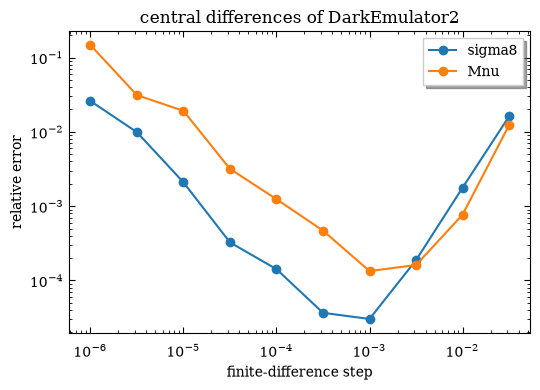

In [ ]:
z_cl = np.linspace(0.0, 1.0, 61)
k_cl = np.logspace(-3, 2, 301)
ell = np.logspace(1, 4, 30)
names = ["Omega_m", "sigma8", "h0", "ns", "omega_b", "Mnu", "w0", "wa", "Omega_k"]


def ln_cl(theta):
    return jnp.log(
        emu.get_cl_limber(
            {**fiducial, **dict(zip(names, theta))}, zlist=z_cl, klist=k_cl, llist=ell
        )[1]
    )


theta0 = jnp.array([fiducial[n] for n in names])
jac_fn = jax.jit(jax.jacfwd(ln_cl))
jac = np.asarray(jac_fn(theta0))


def ln_cl_de2(p):
    return np.log(de.get_cl_limber(p, zlist=z_cl, klist=k_cl, llist=ell)[1])


steps = np.logspace(-1.5, -6, 10)
fig, ax = plt.subplots(figsize=(5.5, 4))
for name in ["sigma8", "Mnu"]:
    i = names.index(name)
    errors = []
    for h in steps:
        fd = (
            ln_cl_de2({**fiducial, name: fiducial[name] + h})
            - ln_cl_de2({**fiducial, name: fiducial[name] - h})
        ) / (2 * h)
        errors.append(np.max(np.abs(fd - jac[:, i])) / np.max(np.abs(jac[:, i])))
    ax.loglog(steps, errors, "o-", label=name)
ax.set_xlabel("finite-difference step")
ax.set_ylabel("relative error")
ax.set_title("central differences of DarkEmulator2")
ax.legend()
plt.tight_layout()
plt.show()

## NUTS: recover the fake-data parameters

Fit `Omega_m`, `sigma8`, `h0` and `ns` to noiseless nonlinear total-matter `P(k,z)` at four redshifts, keeping the other parameters fixed. The mock data use `Omega_m = 0.45`, `sigma8 = 0.62`, with `sigma_logpk = 0.05` in the likelihood.

Two chains each retain 5,000 draws after 1,000 warmup steps. Reduce `n_samples` for a shorter trial.
The text output reports runtime, minimum ESS, maximum R-hat and divergences. ESS estimates the number of independent draws; R-hat should be near 1 and divergences should be zero.

The corner plot shows 15%, 38%, 68% and 95% posterior regions, with the mock-data truth in red. Titles give the medians and central 68% intervals.


In [ ]:
from itertools import product

z_data = np.array([0.0, 0.5, 1.0, 2.0])
k_data = np.logspace(-2, np.log10(5.0), 32)
sigma_logpk = 0.05

sampled_names = ["Omega_m", "sigma8", "h0", "ns"]
prior_bounds = {
    "Omega_m": (0.40, 0.50),
    "sigma8": (0.56, 0.68),
    "h0": (0.64, 0.71),
    "ns": (0.94, 0.99),
    "omega_b": (0.021, 0.0235),
    "Mnu": (0.0, 0.30),
    "w0": (-1.2, -0.8),
    "wa": (-0.3, 0.3),
    "Omega_k": (-0.03, 0.03),
}
# To sample all nine parameters, use: sampled_names = list(prior_bounds)
truth_param = {**fiducial, "Omega_m": 0.45, "sigma8": 0.62}
truth = np.array([truth_param[name] for name in sampled_names])
corners = product(*(prior_bounds[name] for name in sampled_names))
assert all(
    de.is_in_support({**truth_param, **dict(zip(sampled_names, point))})
    for point in corners
)


def model_ln_pk(theta):
    param = {**truth_param, **dict(zip(sampled_names, theta))}
    return jnp.log(
        emu.get_pk(param, zred=z_data, klist=k_data, pk_type="total")[1]
    ).reshape(-1)


theta_truth = jnp.array(truth)
log_pk_data = model_ln_pk(theta_truth)


def model():
    theta = jnp.stack(
        [
            numpyro.sample(name, dist.Uniform(*prior_bounds[name]))
            for name in sampled_names
        ]
    )
    numpyro.sample("obs", dist.Normal(model_ln_pk(theta), sigma_logpk), obs=log_pk_data)

In [ ]:
from numpyro.diagnostics import summary

n_warmup, n_samples, n_chains = 1000, 5000, 2
t0 = time.perf_counter()
kernel = NUTS(model, dense_mass=True, target_accept_prob=0.9)
mcmc = MCMC(
    kernel,
    num_warmup=n_warmup,
    num_samples=n_samples,
    num_chains=n_chains,
    chain_method="sequential",
    progress_bar=False,
)
mcmc.run(jax.random.PRNGKey(0))
samples_by_chain = mcmc.get_samples(group_by_chain=True)
diagnostics = summary(samples_by_chain, group_by_chain=True)
divergences = int(np.asarray(mcmc.get_extra_fields()["diverging"]).sum())
sampling_seconds = time.perf_counter() - t0
samples = {
    name: np.asarray(values).reshape(-1) for name, values in samples_by_chain.items()
}

min_ess = min(float(stat["n_eff"]) for stat in diagnostics.values())
max_rhat = max(float(stat["r_hat"]) for stat in diagnostics.values())
print(
    f"NUTS: {n_chains} chains, {n_chains * n_samples:,} retained draws; {sampling_seconds / 60:.1f} min"
)
print(
    f"Minimum ESS: {min_ess:,.0f} | Maximum R-hat: {max_rhat:.4f} | Divergences: {divergences}"
)


NUTS: 2 chains, 10,000 retained draws; 10.6 min
Minimum ESS: 1,596 | Maximum R-hat: 1.0018 | Divergences: 0


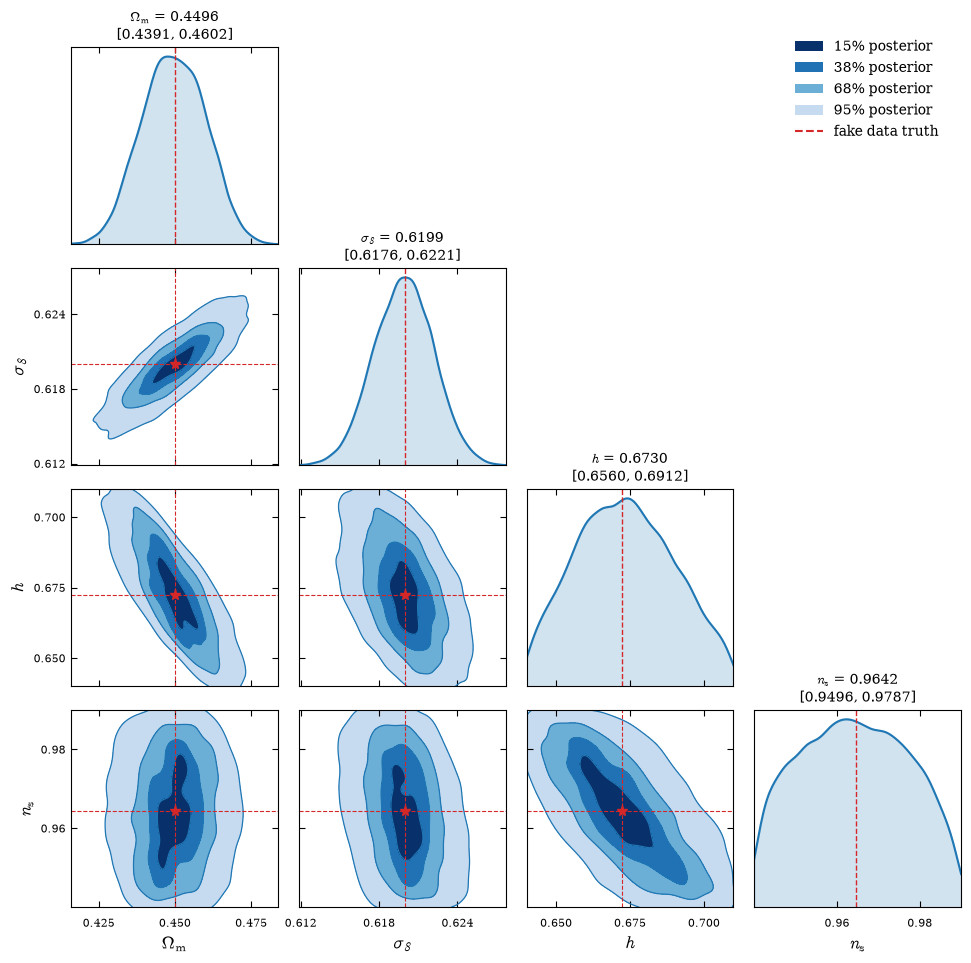

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

labels = {
    "Omega_m": r"$\Omega_{\rm m}$",
    "sigma8": r"$\sigma_8$",
    "h0": r"$h$",
    "ns": r"$n_{\rm s}$",
    "omega_b": r"$\omega_{\rm b}$",
    "Mnu": r"$M_\nu\,[{\rm eV}]$",
    "w0": r"$w_0$",
    "wa": r"$w_a$",
    "Omega_k": r"$\Omega_k$",
}
# Show the posterior at a useful scale while respecting the prior boundaries.
plot_limits = {}
for name in sampled_names:
    lo, hi = np.quantile(samples[name], [0.001, 0.999])
    padding = 0.08 * (hi - lo)
    plot_limits[name] = (
        max(prior_bounds[name][0], lo - padding),
        min(prior_bounds[name][1], hi + padding),
    )

ndim = len(sampled_names)
fig, axes = plt.subplots(ndim, ndim, figsize=(2.5 * ndim, 2.5 * ndim), squeeze=False)
for row, yname in enumerate(sampled_names):
    for col, xname in enumerate(sampled_names):
        ax = axes[row, col]
        if col > row:
            ax.set_visible(False)
            continue
        x = np.linspace(*plot_limits[xname], 160)
        if row == col:
            density = gaussian_kde(samples[xname])(x)
            ax.fill_between(x, density, color="C0", alpha=0.20)
            ax.plot(x, density, color="C0", lw=1.5)
            ax.axvline(truth_param[xname], color="C3", ls="--", lw=1)
            ax.set_ylim(bottom=0)
            ax.set_yticks([])
            lo, mid, hi = np.quantile(samples[xname], [0.16, 0.50, 0.84])
            ax.set_title(
                f"{labels[xname]} = {mid:.4f}\n[{lo:.4f}, {hi:.4f}]", fontsize=10
            )
        else:
            y = np.linspace(*plot_limits[yname], 160)
            xx, yy = np.meshgrid(x, y)
            density = gaussian_kde(np.vstack([samples[xname], samples[yname]]))(
                np.vstack([xx.ravel(), yy.ravel()])
            ).reshape(xx.shape)
            ordered = np.sort(density.ravel())[::-1]
            mass = np.cumsum(ordered) / ordered.sum()
            levels = [
                ordered[min(np.searchsorted(mass, prob), len(ordered) - 1)]
                for prob in [0.95, 0.68, 0.38, 0.15]
            ]
            ax.contourf(
                xx,
                yy,
                density,
                levels=[*levels, density.max() * 1.001],
                colors=["#c6dbef", "#6baed6", "#2171b5", "#08306b"],
            )
            ax.contour(xx, yy, density, levels=levels, colors="C0", linewidths=0.9)
            ax.axvline(truth_param[xname], color="C3", ls="--", lw=0.8)
            ax.axhline(truth_param[yname], color="C3", ls="--", lw=0.8)
            ax.plot(truth_param[xname], truth_param[yname], "*", color="C3", ms=8)
            ax.set_ylim(*plot_limits[yname])
        ax.set_xlim(*plot_limits[xname])
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3, prune="both"))
        if row != col:
            ax.yaxis.set_major_locator(MaxNLocator(nbins=3, prune="both"))
        ax.tick_params(direction="in", top=True, right=True, labelsize=8)
        if row == ndim - 1:
            ax.set_xlabel(labels[xname], fontsize=13)
        else:
            ax.tick_params(labelbottom=False)
        if col == 0 and row > 0:
            ax.set_ylabel(labels[yname], fontsize=13)
        elif row != col:
            ax.tick_params(labelleft=False)

fig.legend(
    handles=[
        Patch(facecolor="#08306b", label="15% posterior"),
        Patch(facecolor="#2171b5", label="38% posterior"),
        Patch(facecolor="#6baed6", label="68% posterior"),
        Patch(facecolor="#c6dbef", label="95% posterior"),
        Line2D([], [], color="C3", ls="--", label="fake data truth"),
    ],
    loc="upper right",
    bbox_to_anchor=(0.97, 0.96),
    frameon=False,
)
fig.subplots_adjust(
    left=0.09, right=0.98, bottom=0.08, top=0.94, hspace=0.12, wspace=0.10
)
plt.show()